# Resultado principal: el modelo frente al canal endémico

Este cuaderno vuelve a calcular, desde los datos publicados en este mismo
repositorio, la tabla central del informe: cuántos inicios de brote anticipa
la regresión logística con clima frente al canal endémico condicionado,
cuando los dos emiten **el mismo número de alertas cada mes**.

**Qué necesita.** Solo este repositorio y el entorno del proyecto
(`uv sync --locked --project pipeline`). No hace falta token, ni reconstruir
el panel, ni reentrenar: lee el panel de `datos/panel/` y las predicciones ya
versionadas en `docs/evidence/`.

**Qué produce.** Las cuatro filas de la Tabla 2 del artículo (reconstrucción
2018-2022 y confirmación retrospectiva 2023-2024, en T+1 y T+2) y la curva de
sensibilidad frente al volumen de alertas de la Figura 2.

**Cuánto tarda.** Alrededor de un minuto.

In [1]:
import hashlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "pipeline" / "src"))
sys.path.insert(0, str(RAIZ / "pipeline" / "tools"))

from exportar_entregable import leer_panel  # noqa: E402
from sat_dengue_pipeline.evaluation import validacion_anual as va  # noqa: E402

PANEL = RAIZ / "datos" / "panel"
PREDICCIONES = (
    RAIZ / "docs" / "evidence" / "reserva-2023-2024-t2" / "predicciones_log_conclima.csv"
)

## 1. El panel

`datos/panel/panel_meta_tolima.csv` son los agregados municipio-mes de Meta y
Tolima entre 2007 y 2024. `esquema.json` acompaña al CSV y dice qué tipo tiene
cada columna, qué papel cumple y de dónde salió; se usa aquí para restaurar los
tipos exactos, porque un CSV por sí solo no los conserva.

In [2]:
panel, esquema = leer_panel(PANEL)
descrito = esquema["panel"]
print(f"panel: {len(panel)} filas | {panel.municipality_code.nunique()} municipios "
      f"| {panel.year_month.min()} a {panel.year_month.max()}")
print(f"huella semántica del artefacto de origen: {descrito['huella_semantica'][:16]}…")

panel: 16416 filas | 76 municipios | 2007-01 a 2024-12
huella semántica del artefacto de origen: de49b11bad43c359…


## 2. Las predicciones

Son las de la receta `log_conclima`, producidas por el arnés de retroanálisis
con validación de origen móvil: en cada mes de origen el modelo se reentrena
solo con filas cuya etiqueta ya era observable, y predice únicamente las filas
de ese origen. Aquí no se reentrena nada; se leen tal como quedaron.

In [3]:
predicciones = pd.read_csv(PREDICCIONES, dtype={"municipality_code": str})
print(f"predicciones: {len(predicciones)} filas"
      f" | horizontes {sorted(predicciones.horizon.unique())}")
print(f"orígenes: {predicciones.origin_period.min()} a {predicciones.origin_period.max()}")
print(f"sha256 del archivo: {hashlib.sha256(PREDICCIONES.read_bytes()).hexdigest()[:16]}…")

predicciones: 8124 filas | horizontes [np.int64(1), np.int64(2)]
orígenes: 2018-01 a 2024-10
sha256 del archivo: 5854df580bfe97ae…


## 3. La cohorte evaluable

`desde_pipeline` cruza panel y predicciones y deriva del panel —no de las
predicciones— el exceso, el mes objetivo y el inicio. Un mes está en exceso
cuando sus casos superan el percentil 75 del mismo mes calendario en los cinco
años anteriores del propio municipio; un **inicio** es el primer mes en exceso
después de uno que no lo estaba.

`validar_entrada` conserva los años evaluados más el previo, que hace falta
para elegir la fracción del canal sin mirar el año que se evalúa.

In [4]:
def cohorte(horizonte: int) -> pd.DataFrame:
    """Construir la tabla de evaluación de un horizonte, con todos sus años."""
    q = predicciones[predicciones.horizon == horizonte].drop(columns="receta", errors="ignore")
    marco = va.desde_pipeline(panel, q, str(q.candidate.iloc[0]), horizonte)
    anios = tuple(sorted(int(a) for a in marco.anio_objetivo.unique() if a < 2025))
    return va.validar_entrada(marco, anios)


cohortes = {h: cohorte(h) for h in (1, 2)}
for h, d in cohortes.items():
    print(f"T+{h}: {len(d)} filas evaluables, {int((d.inicio == 1).sum())} inicios")

T+1: 4082 filas evaluables, 641 inicios
T+2: 4042 filas evaluables, 459 inicios


## 4. Presupuesto común e intervalo

El presupuesto de referencia es el 10 % de los 76 municipios por mes de origen.
Se recorre la rejilla de fracciones del canal y se toma aquella cuyo número de
alertas queda más cerca de ese objetivo; después el modelo emite **exactamente
el mismo número de alertas en cada mes**, asignadas a sus puntajes más altos.
Así una ventaja no puede venir de alertar más.

El intervalo se obtiene remuestreando bloques de mes de origen, que conserva
juntos los municipios de un mismo mes y el emparejamiento entre métodos. La
función `boot` es **copia literal** de `pipeline/tools/noche/veredicto.py`,
incluida la semilla derivada de la celda: así el intervalo de una receta no
depende de cuántas otras se evalúen en la misma corrida. La celda 6 comprueba
que esta reproducción coincide con la evidencia original.

In [5]:
MUNICIPIOS = 76


def boot(d, x, grupo, clave, n=2000):
    """IC 95 % de la suma de x remuestreando bloques del grupo (copia de veredicto.py)."""
    semilla = int.from_bytes(hashlib.sha256(str(clave).encode()).digest()[:8], "big")
    rng = np.random.default_rng(semilla)
    s = pd.Series(x, index=d.index).groupby(d[grupo]).sum().values
    b = rng.choice(s, size=(n, len(s)), replace=True).sum(axis=1)
    return float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))


def evaluar(horizonte: int, anios: tuple[int, ...], fraccion: float = 0.10) -> dict:
    """Comparar canal y modelo sobre los años dados, al presupuesto indicado."""
    d = cohortes[horizonte]
    d = d[d.anio_objetivo.isin(anios)].reset_index(drop=True)
    n, ini = len(d), (d.inicio.values == 1)
    meses = d.origen.nunique()
    total = MUNICIPIOS * meses
    curva = [(f, va.canal(d, f, fuera_exceso=True)) for f in va.GRILLA_F]
    f, a_c = min(curva, key=lambda t: abs(int(t[1].sum()) - fraccion * total))
    a_m = va.emparejar(d, a_c)
    mc, mm = va.metricas(a_c, d), va.metricas(a_m, d)
    dif = (a_m - a_c) * ini
    carga = (a_m - a_c) * (~ini) * 100 / n
    # La clave de la semilla usa el nombre de receta del evaluador original,
    # para que el intervalo salga idéntico al publicado.
    lo_o, hi_o = boot(d, dif, "origen", ("log_conclima", horizonte, fraccion, "dif_origen"))
    lo_c, hi_c = boot(d, carga, "origen", ("log_conclima", horizonte, fraccion, "carga_origen"))
    inicios = mc["inicios"]
    return {
        "horizonte": f"T+{horizonte}",
        "f": f,
        "alertas": int(a_c.sum()),
        "alertas_mes": round(a_c.sum() / meses, 1),
        "filas": n,
        "inicios": inicios,
        "canal": mc["inicios_detectados"],
        "modelo": mm["inicios_detectados"],
        "dif_pp": round(100 * dif.sum() / inicios, 1),
        "ic_pp": f"{100 * lo_o / inicios:.1f} a {100 * hi_o / inicios:.1f}",
        "dif_carga": round(mm["carga_100mm"] - mc["carga_100mm"], 2),
        "ic_carga": f"{lo_c:.2f} a {hi_c:.2f}",
        "barra_5pp": "CUMPLE" if (100 * dif.sum() / inicios) >= 5 and lo_o > 0 else "NO CUMPLE",
    }

## 5. La Tabla 2 del artículo

Dos periodos: 2018-2022 reconstruye la etapa en la que se seleccionó la
configuración, y 2023-2024 es la confirmación retrospectiva.

In [6]:
PERIODOS = {
    "Reconstrucción 2018-2022": tuple(range(2018, 2023)),
    "Confirmación 2023-2024": (2023, 2024),
}

tabla2 = pd.DataFrame(
    [{"periodo": nombre, **evaluar(h, anios)} for nombre, anios in PERIODOS.items() for h in (1, 2)]
)
tabla2.sort_values(["periodo", "horizonte"], inplace=True, ignore_index=True)
tabla2

,periodo,horizonte,f,alertas,alertas_mes,filas,inicios,canal,modelo,dif_pp,ic_pp,dif_carga,ic_carga,barra_5pp
0,Confirmación 2023-2024,T+1,0.95,181,7.9,824,224,98,103,2.2,-1.3 a 5.8,-0.61,-1.58 a 0.36,NO CUMPLE
1,Confirmación 2023-2024,T+2,0.95,200,8.7,836,147,57,70,8.8,1.4 a 16.3,-1.56,-2.87 a -0.24,CUMPLE
2,Reconstrucción 2018-2022,T+1,0.80,444,7.5,3258,417,180,198,4.3,0.5 a 7.9,-0.55,-1.04 a -0.06,NO CUMPLE
3,Reconstrucción 2018-2022,T+2,0.90,442,7.6,3206,312,97,118,6.7,2.2 a 11.2,-0.66,-1.09 a -0.22,CUMPLE


## 6. Comprobación contra lo publicado

Las cuatro filas tienen evidencia original en `docs/evidence/`, producida en su
momento por `veredicto.py`: las de 2023-2024 en `reserva-2023-2024-t2/reserva.csv`
y las cuatro en `comparacion-familias-t58/comparacion_familias.csv`. Son las
mismas cifras que aparecen en la Tabla 2 del artículo. Si esta reproducción no
diera exactamente lo mismo, el cuaderno falla aquí en lugar de mostrar una tabla
que se parece.

In [7]:
PUBLICADO = {
    ("Reconstrucción 2018-2022", "T+1"):
        dict(alertas=444, inicios=417, canal=180, modelo=198, dif_pp=4.3),
    ("Reconstrucción 2018-2022", "T+2"):
        dict(alertas=442, inicios=312, canal=97, modelo=118, dif_pp=6.7),
    ("Confirmación 2023-2024", "T+1"):
        dict(alertas=181, inicios=224, canal=98, modelo=103, dif_pp=2.2),
    ("Confirmación 2023-2024", "T+2"):
        dict(alertas=200, inicios=147, canal=57, modelo=70, dif_pp=8.8),
}

for (periodo, horizonte), esperado in PUBLICADO.items():
    fila = tabla2[(tabla2.periodo == periodo) & (tabla2.horizonte == horizonte)].iloc[0]
    for campo, valor in esperado.items():
        assert fila[campo] == valor, f"{periodo} {horizonte}: {campo} dio {fila[campo]}, no {valor}"
print("Las cuatro filas de la Tabla 2 se reproducen exactamente desde el panel publicado.")

Las cuatro filas de la Tabla 2 se reproducen exactamente desde el panel publicado.


## 7. ¿La ventaja depende de alertar más?

La comparación anterior fija un presupuesto. Esta celda lo recorre: 5, 10, 15,
20 y 30 % de los municipios por mes. En los dos métodos el número de alertas es
el mismo en cada punto, así que lo que cambia es solo cuánto cabe en la lista.

In [8]:
FRACCIONES = (0.05, 0.10, 0.15, 0.20, 0.30)
curva = pd.DataFrame(
    [
        {"fraccion": frac, **evaluar(h, PERIODOS["Confirmación 2023-2024"], frac)}
        for h in (1, 2)
        for frac in FRACCIONES
    ]
)
COLUMNAS_CURVA = ["horizonte", "fraccion", "alertas_mes", "inicios", "canal", "modelo",
                  "dif_pp", "ic_pp"]
curva.loc[:, COLUMNAS_CURVA]

,horizonte,fraccion,alertas_mes,inicios,canal,modelo,dif_pp,ic_pp
0,T+1,0.05,3.8,224,59,58,-0.4,-3.6 a 2.2
1,T+1,0.10,7.9,224,98,103,2.2,-1.3 a 5.8
2,T+1,0.15,11.3,224,129,136,3.1,-1.8 a 8.0
3,T+1,0.20,15.6,224,147,165,8.0,4.0 a 12.1
4,T+1,0.30,23.2,224,166,191,11.2,7.1 a 15.2
5,T+2,0.05,3.9,147,29,35,4.1,-1.4 a 9.5
6,T+2,0.10,8.7,147,57,70,8.8,1.4 a 16.3
7,T+2,0.15,11.5,147,68,83,10.2,3.4 a 17.0
8,T+2,0.20,15.5,147,85,98,8.8,2.0 a 15.6
9,T+2,0.30,23.0,147,104,121,11.6,5.4 a 18.4


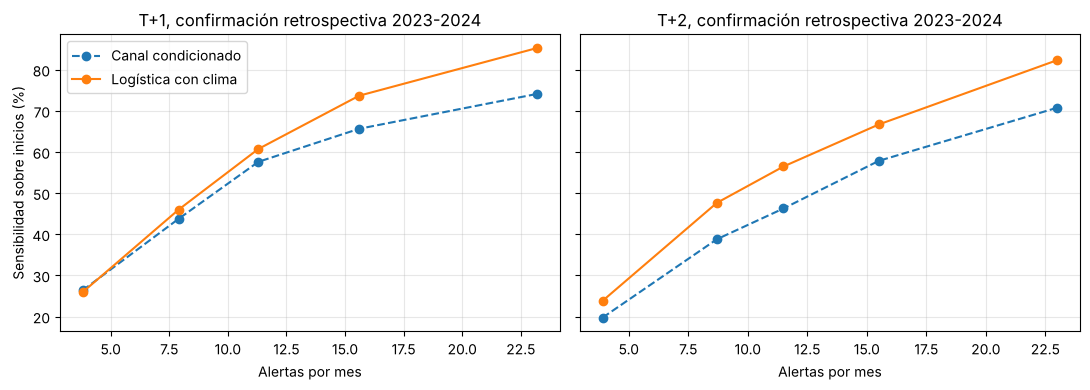

In [9]:
figura, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for eje, h in zip(ejes, ("T+1", "T+2")):
    parte = curva[curva.horizonte == h]
    for metodo, estilo in (("canal", "o--"), ("modelo", "o-")):
        eje.plot(
            parte.alertas_mes,
            100 * parte[metodo] / parte.inicios,
            estilo,
            label="Canal condicionado" if metodo == "canal" else "Logística con clima",
        )
    eje.set_title(f"{h}, confirmación retrospectiva 2023-2024")
    eje.set_xlabel("Alertas por mes")
    eje.grid(alpha=0.3)
ejes[0].set_ylabel("Sensibilidad sobre inicios (%)")
ejes[0].legend()
figura.tight_layout()
plt.show()

## 8. ¿Cuánto hay disponible para ganar?

La comparación anterior dice cuánto gana el modelo sobre el canal. No dice
cuánto **había** para ganar. Esta celda lo mide con dos anclas, al mismo
presupuesto y sobre las mismas filas:

- **El techo** es un oráculo que ordena los municipios conociendo el mes
  objetivo. Es el máximo alcanzable por cualquier modelo a ese cupo. No es una
  predicción ni una cota de generalización: ve la respuesta, y no se reporta
  como resultado del modelo en ningún lado.
- **El piso** es la alerta aleatoria al mismo cupo.

Entre los dos queda la escala contra la que conviene leer la diferencia de 5
puntos que el proyecto se fijó como barra.

In [10]:
def escala(horizonte: int, anios: tuple[int, ...], fraccion: float = 0.10) -> list[dict]:
    """Medir canal, modelo, techo y piso sobre las mismas filas y el mismo cupo."""
    d = cohortes[horizonte]
    d = d[d.anio_objetivo.isin(anios)].reset_index(drop=True)
    meses = d.origen.nunique()
    curva = [(f, va.canal(d, f, fuera_exceso=True)) for f in va.GRILLA_F]
    _, a_canal = min(curva, key=lambda t: abs(int(t[1].sum()) - fraccion * MUNICIPIOS * meses))
    generador = np.random.default_rng(42)
    metodos = {
        "canal": a_canal,
        "modelo": va.emparejar(d, a_canal),
        "techo": va.emparejar(d.assign(score=d.inicio.astype(float)), a_canal),
        "piso": va.emparejar(d.assign(score=generador.random(len(d))), a_canal),
    }
    return [
        {
            "horizonte": f"T+{horizonte}",
            "metodo": metodo,
            "alertas_mes": round(a.sum() / meses, 1),
            "detectados": va.metricas(a, d)["inicios_detectados"],
            "inicios": va.metricas(a, d)["inicios"],
            "sensibilidad": round(100 * va.metricas(a, d)["sensibilidad_inicios"], 1),
        }
        for metodo, a in metodos.items()
    ]


anclas = pd.DataFrame(
    [f for h in (1, 2) for f in escala(h, PERIODOS["Confirmación 2023-2024"])]
)
anclas

,horizonte,metodo,alertas_mes,detectados,inicios,sensibilidad
0,T+1,canal,7.9,98,224,43.8
1,T+1,modelo,7.9,103,224,46.0
2,T+1,techo,7.9,154,224,68.8
3,T+1,piso,7.9,63,224,28.1
4,T+2,canal,8.7,57,147,38.8
5,T+2,modelo,8.7,70,147,47.6
6,T+2,techo,8.7,131,147,89.1
7,T+2,piso,8.7,38,147,25.9


In [11]:
for h in ("T+1", "T+2"):
    p = anclas[anclas.horizonte == h].set_index("metodo").sensibilidad
    disponible = p["techo"] - p["canal"]
    print(f"{h}: piso {p['piso']} % | canal {p['canal']} % | modelo {p['modelo']} % "
          f"| techo {p['techo']} %")
    print(f"     el modelo captura {p['modelo'] - p['canal']:.1f} pp de los "
          f"{disponible:.1f} disponibles sobre el canal "
          f"({100 * (p['modelo'] - p['canal']) / disponible:.0f} %)")

T+1: piso 28.1 % | canal 43.8 % | modelo 46.0 % | techo 68.8 %
     el modelo captura 2.2 pp de los 25.0 disponibles sobre el canal (9 %)
T+2: piso 25.9 % | canal 38.8 % | modelo 47.6 % | techo 89.1 %
     el modelo captura 8.8 pp de los 50.3 disponibles sobre el canal (17 %)


El piso cae cerca de la fracción de filas que reciben alerta, que es lo que
debe pasar si el orden es puro azar: sirve de comprobación de que el arnés no
está regalando detecciones por construcción.

Lo que dice el techo es que **el presupuesto no es la restricción, el orden
sí**. A ocho alertas por mes cabe mucho más de lo que cualquiera de los dos
métodos encuentra, y el modelo se queda con una fracción del margen. Eso, junto
con que cerca de un tercio de los inicios arranca sin casos notificados —donde
ningún método basado en conteos tiene nada que ordenar—, es el argumento para
que el trabajo futuro apunte a información nueva y no a modelos más complejos
sobre las mismas variables.

## Lectura

En T+2 la logística con clima supera al canal en los cinco presupuestos, y al
presupuesto de referencia la mejora es de 8,8 puntos porcentuales con la cota
inferior del intervalo por encima de cero. En T+1 las dos curvas van casi
pegadas en los presupuestos bajos y la diferencia no es concluyente: por eso el
informe toma T+2 como horizonte principal y no reporta T+1 como una victoria.

Conviene no perder de vista lo que queda fuera: incluso en T+2, más de la mitad
de los inicios no los anticipa ninguno de los dos métodos.